In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib
import json
import re
import ast
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from scipy.sparse import save_npz, load_npz

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
print("Files available in /content:\n")

for filename in os.listdir('/content'):
    print(filename)

Files available in /content:

.config
TED_Talks_Cleaned_Dataset.csv
TED_Talks_EDA_Prepared.csv
sample_data


In [6]:
df = pd.read_csv('/content/TED_Talks_EDA_Prepared.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4016, 25)


,Talk_Id,Title,Speaker_1,All_Speakers,Occupations,About_speakers,Views,Recorded_date,Published_date,Event,...,Related_talks,URL,Description,Transcript,Topic_Count,Title_Word_Count,Description_Word_Count,Transcript_Word_Count,About_speakers_Word_Count,Combined_Text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392.0,25-02-2006,27-06-2006,TED2006,...,"{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",9,4,39,2153,24,Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685.0,22-02-2006,27-06-2006,TED2006,...,"{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",11,6,26,3174,35,"The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832.0,24-02-2006,27-06-2006,TED2006,...,"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",9,2,31,3371,45,"Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069.0,26-02-2006,27-06-2006,TED2006,...,{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,9,3,31,3071,32,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954.0,25-02-2006,27-06-2006,TED2006,...,"{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,7,4,21,3170,32,"Do schools kill creativity? ['children', 'crea..."


In [7]:
required_columns = [
    'Title',
    'Topics',
    'Transcript'
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available!")

display(df[required_columns].head())

All required columns are available!


,Title,Topics,Transcript
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...","Thank you so much, Chris. And it's truly a gre..."
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...","About 10 years ago, I took on the task to teac..."
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...","(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...",If you're here today — and I'm very happy that...
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...",Good morning. How are you? (Audience) Good. It...


**Prepare the dataset for recommendation :**
---



In [8]:
df = df.copy()

# Clean the required text columns
for col in required_columns:
    df[col] = (
        df[col]
        .fillna('')
        .astype(str)
        .str.strip()
    )

# Remove records without a usable title or transcript
df = df[
    df['Title'].ne('') &
    df['Transcript'].ne('')
].copy()

# Remove duplicate titles for this implementation
df = df.drop_duplicates(
    subset=['Title'],
    keep='first'
).reset_index(drop=True)

# Combine the fields used for recommendation
df['Combined_Text'] = (
    df['Title'] + ' ' +
    df['Topics'] + ' ' +
    df['Transcript']
).str.strip()

print("Dataset preparation completed!")
print("Prepared dataset shape:", df.shape)

display(
    df[['Title', 'Topics', 'Combined_Text']].head()
)

Dataset preparation completed!
Prepared dataset shape: (4016, 25)


,Title,Topics,Combined_Text
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis ['alternative ener...
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...","The best stats you've ever seen ['Africa', 'As..."
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...","Simplicity sells ['computers', 'entertainment'..."
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...","Greening the ghetto ['MacArthur grant', 'activ..."
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...","Do schools kill creativity? ['children', 'crea..."


**Split the dataset into training and testing sets:**
---



In [9]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Dataset split completed!")
print("--------------------------------")
print("Total talks:", len(df))
print("Training talks:", len(train_df))
print("Testing talks:", len(test_df))
print("--------------------------------")

print("\nTraining dataset sample:")
display(train_df[['Title', 'Topics']].head())

print("\nTesting dataset sample:")
display(test_df[['Title', 'Topics']].head())

Dataset split completed!
--------------------------------
Total talks: 4016
Training talks: 3212
Testing talks: 804
--------------------------------

Training dataset sample:


,Title,Topics
0,Can we choose to fall out of love?,"['love', 'music', 'life', 'neuroscience', 'art..."
1,How protest is redefining democracy around the...,"['activism', 'Africa', 'corruption', 'leadersh..."
2,Why is cotton in everything?,"['TED-Ed', 'history', 'animation', 'farming', ..."
3,Extreme swimming with the world's most dangero...,"['culture', 'extreme sports', 'fear', 'sports'..."
4,Can you solve the famously difficult green-eye...,"['philosophy', 'psychology', 'sociology', 'TED..."



Testing dataset sample:


,Title,Topics
0,The beautiful math behind the world's ugliest ...,"['TEDx', 'entertainment', 'math', 'music', 'sc..."
1,ET is (probably) out there -- get ready,"['TEDx', 'astronomy', 'extraterrestrial life',..."
2,The human stories behind mass incarceration,"['activism', 'community', 'family', 'justice s..."
3,Are droids taking our jobs?,"['TEDx', 'business', 'technology', 'robots', '..."
4,A love story for the coral reef crisis,"['fish', 'oceans', 'sustainability', 'nature',..."


**Create and train the vectorizer :**
---



In [10]:
# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    dtype=np.float32
)

# Fit only on training data
train_tfidf_matrix = tfidf_vectorizer.fit_transform(
    train_df['Combined_Text']
)

print("TF-IDF model training completed!")
print("----------------------------------")
print("Training talks:", train_tfidf_matrix.shape[0])
print("TF-IDF features:", train_tfidf_matrix.shape[1])
print("Matrix type:", type(train_tfidf_matrix))
print("Matrix shape:", train_tfidf_matrix.shape)

TF-IDF model training completed!
----------------------------------
Training talks: 3212
TF-IDF features: 10000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix shape: (3212, 10000)


**Calculate training-talk similarities :**
---



In [11]:
# Calculate similarities between training talks
train_similarity_matrix = cosine_similarity(
    train_tfidf_matrix,
    dense_output=False
)

print("Training similarity matrix created!")
print("Matrix shape:", train_similarity_matrix.shape)
print("Number of training talks:", len(train_df))

Training similarity matrix created!
Matrix shape: (3212, 3212)
Number of training talks: 3212


**Create a recommendation function :**
---



In [12]:
def recommend_from_training(talk_title, top_n=5):

    # Find the selected talk in the full dataset
    matches = df.index[
        df['Title'].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk title not found in the dataset.")
        return pd.DataFrame()

    selected_index = matches[0]
    selected_talk = df.loc[selected_index]

    # Transform the selected talk using the training vocabulary
    query_vector = tfidf_vectorizer.transform(
        [selected_talk['Combined_Text']]
    )

    # Compare the selected talk with all training talks
    scores = cosine_similarity(
        query_vector,
        train_tfidf_matrix
    ).ravel()

    # Exclude the selected talk itself if it exists in training
    same_title = (
        train_df['Title'].str.casefold()
        == talk_title.casefold()
    ).to_numpy()

    scores[same_title] = -1

    # Select the most similar training talks
    top_indices = np.argsort(scores)[::-1][:top_n]

    recommendations = train_df.iloc[top_indices][
        ['Title', 'Topics']
    ].copy()

    recommendations['Similarity_Score'] = scores[top_indices]

    return recommendations.reset_index(drop=True)


print("Recommendation function created successfully!")

Recommendation function created successfully!


**Test the recommendation engine :**
---



In [13]:
sample_title = test_df.iloc[0]['Title']

print("Selected TED Talk:")
print(sample_title)

print("\nRecommended TED Talks:")

recommendations = recommend_from_training(
    sample_title,
    top_n=5
)

display(recommendations)

Selected TED Talk:
The beautiful math behind the world's ugliest music

Recommended TED Talks:


,Title,Topics,Similarity_Score
0,Why we love repetition in music,"['consciousness', 'psychology', 'music', 'TED-...",0.397835
1,How AI could compose a personalized soundtrack...,"['music', 'AI', 'algorithm', 'future', 'creati...",0.356509
2,The mad scientist of music,"['TEDx', 'art', 'composing', 'music', 'creativ...",0.336878
3,How music makes me a better neuroscientist,"['science', 'music', 'art', 'brain', 'neurosci...",0.335797
4,La música de las ideas,"['art', 'creativity', 'music', 'live music', '...",0.327680


**Evaluate the recommendation engine :**
---

Prepare topics for evaluation :-

---



In [14]:
def parse_topics(value):

    if pd.isna(value):
        return set()

    text = str(value).strip()

    if not text:
        return set()

    # Handle list-like strings, such as "['AI', 'technology']"
    if text.startswith('[') and text.endswith(']'):
        try:
            parsed = ast.literal_eval(text)

            if isinstance(parsed, (list, tuple, set)):
                return {
                    str(topic).strip().casefold()
                    for topic in parsed
                    if str(topic).strip()
                }

        except (ValueError, SyntaxError):
            pass

    # Handle comma-separated or semicolon-separated topics
    topics = re.split(r'[,;|]', text)

    return {
        topic.strip().casefold()
        for topic in topics
        if topic.strip()
    }


train_topic_sets = [
    parse_topics(topics)
    for topics in train_df['Topics']
]

test_topic_sets = [
    parse_topics(topics)
    for topics in test_df['Topics']
]

print("Topic parsing completed!")
print("Example topic set:", train_topic_sets[0])

Topic parsing completed!
Example topic set: {'memory', 'life', 'love', 'relationships', 'neuroscience', 'brain', 'mind', 'music', 'tedx', 'art', 'emotions', 'rap', 'vulnerability'}


**Evaluate Precision@5 and Recall@5 :**
---



In [15]:
def evaluate_recommendations(k=5):

    precision_scores = []
    recall_scores = []

    for test_position in range(len(test_df)):

        query_text = test_df.loc[
            test_position, 'Combined_Text'
        ]

        query_topics = test_topic_sets[test_position]

        # Skip talks with no usable topics
        if not query_topics:
            continue

        query_vector = tfidf_vectorizer.transform(
            [query_text]
        )

        # Compare test talk against training talks
        scores = cosine_similarity(
            query_vector,
            train_tfidf_matrix
        ).ravel()

        # Select top-k training talks
        top_indices = np.argsort(scores)[::-1][:k]

        recommended_topics = [
            train_topic_sets[index]
            for index in top_indices
        ]

        # A recommendation is relevant if any topic overlaps
        relevant_flags = [
            bool(query_topics & topics)
            for topics in recommended_topics
        ]

        precision_at_k = sum(relevant_flags) / k

        retrieved_topics = set()

        for topics in recommended_topics:
            retrieved_topics.update(query_topics & topics)

        recall_at_k = (
            len(retrieved_topics) / len(query_topics)
        )

        precision_scores.append(precision_at_k)
        recall_scores.append(recall_at_k)

    if not precision_scores:
        raise ValueError(
            "No test talks have usable topics. "
            "Check the Topics column format."
        )

    return {
        'Precision@5': float(np.mean(precision_scores)),
        'Recall@5': float(np.mean(recall_scores)),
        'Evaluated_Test_Talks': len(precision_scores)
    }


evaluation_results = evaluate_recommendations(k=5)

print("Offline Evaluation Results")
print("--------------------------------")

for metric, value in evaluation_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Offline Evaluation Results
--------------------------------
Precision@5: 0.8614
Recall@5: 0.6710
Evaluated_Test_Talks: 804


**Plot Precision@5 and Recall@5 :**
---



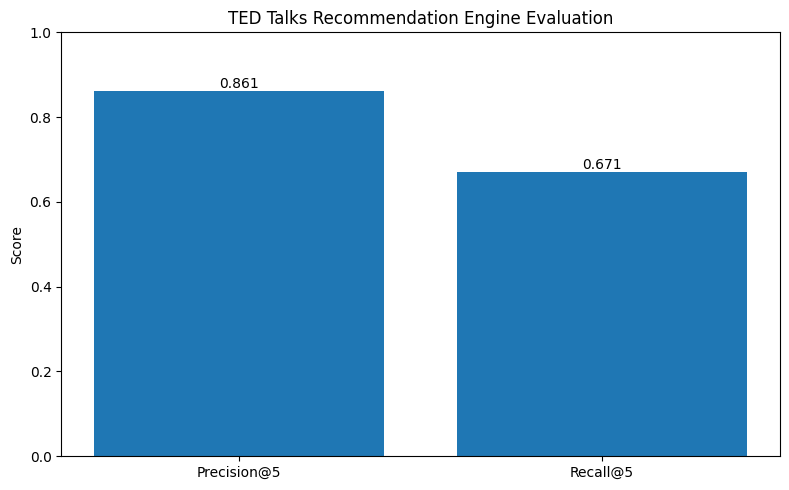

In [16]:
metric_names = [
    'Precision@5',
    'Recall@5'
]

metric_values = [
    evaluation_results['Precision@5'],
    evaluation_results['Recall@5']
]

plt.figure(figsize=(8, 5))

bars = plt.bar(metric_names, metric_values)

plt.title('TED Talks Recommendation Engine Evaluation')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

**Train the final model on the complete dataset :**
---

**1. Fit the final vectorizer :**

---



In [17]:
final_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    dtype=np.float32
)

final_tfidf_matrix = final_vectorizer.fit_transform(
    df['Combined_Text']
)

print("Final model trained successfully!")
print("Total talks:", final_tfidf_matrix.shape[0])
print("Total TF-IDF features:", final_tfidf_matrix.shape[1])

Final model trained successfully!
Total talks: 4016
Total TF-IDF features: 10000


**Create the final recommendation function :**
---



In [18]:
def recommend_ted_talks(talk_title, top_n=5):

    matches = df.index[
        df['Title'].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk title not found in the dataset.")
        return pd.DataFrame()

    selected_index = matches[0]

    query_vector = final_vectorizer.transform(
        [df.loc[selected_index, 'Combined_Text']]
    )

    scores = cosine_similarity(
        query_vector,
        final_tfidf_matrix
    ).ravel()

    # Exclude the selected talk itself
    scores[selected_index] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = df.iloc[top_indices][
        ['Title', 'Topics']
    ].copy()

    results['Similarity_Score'] = scores[top_indices]

    return results.reset_index(drop=True)


print("Final recommendation function created!")

Final recommendation function created!


**Test the final recommendation model :**
---



In [19]:
sample_title = df.iloc[0]['Title']

print("Selected TED Talk:")
print(sample_title)

print("\nRecommended TED Talks:")

display(
    recommend_ted_talks(
        sample_title,
        top_n=5
    )
)

Selected TED Talk:
Averting the climate crisis

Recommended TED Talks:


,Title,Topics,Similarity_Score
0,New thinking on the climate crisis,"['activism', 'climate change', 'global issues'...",0.335722
1,A climate solution where all sides can win,"['big problems', 'business', 'china', 'economi...",0.299986
2,How we can turn the tide on climate,"['climate change', 'environment', 'activism', ...",0.293013
3,A one-man world summit,"['comedy', 'global issues', 'government', 'per...",0.288160
4,The case for optimism on climate change,"['climate change', 'weather', 'science', 'alte...",0.284846


In [30]:
output_dir = '/content/module_4_outputs'

os.makedirs(output_dir, exist_ok=True)

print("Output directory created:")
print(output_dir)

Output directory created:
/content/module_4_outputs


In [31]:
# Save the final TF-IDF vectorizer
joblib.dump(
    final_vectorizer,
    os.path.join(output_dir, 'final_tfidf_vectorizer.pkl')
)

# Save the final sparse TF-IDF matrix
save_npz(
    os.path.join(output_dir, 'final_tfidf_matrix.npz'),
    final_tfidf_matrix
)

# Save the prepared dataset
df.to_csv(
    os.path.join(output_dir, 'prepared_ted_talks.csv'),
    index=False
)

# Save evaluation results
with open(
    os.path.join(output_dir, 'evaluation_results.json'),
    'w',
    encoding='utf-8'
) as file:
    json.dump(
        evaluation_results,
        file,
        indent=4
    )

print("Model and dataset artifacts saved successfully!")

Model and dataset artifacts saved successfully!


In [32]:
training_config = {
    'project': 'TED Talks Recommendation System',
    'recommendation_strategy': 'Content-Based Filtering',
    'text_representation': 'TF-IDF',
    'features_used': [
        'Title',
        'Topics',
        'Transcript'
    ],
    'max_features': 10000,
    'min_df': 2,
    'max_df': 0.95,
    'ngram_range': [1, 2],
    'stop_words': 'english',
    'dtype': 'float32',
    'evaluation_split': '80% training / 20% testing',
    'random_state': 42,
    'evaluation_metrics': [
        'Precision@5',
        'Recall@5'
    ],
    'relevance_definition': (
        'A recommended talk is relevant when it shares '
        'at least one parsed topic with the test talk.'
    ),
    'evaluation_limitation': (
        'Topic overlap is a proxy for relevance, not '
        'a measure of actual user satisfaction.'
    ),
    'collaborative_filtering_status': (
        'Not implemented because user interaction data '
        'is unavailable.'
    )
}

with open(
    os.path.join(output_dir, 'training_configuration.json'),
    'w',
    encoding='utf-8'
) as file:
    json.dump(
        training_config,
        file,
        indent=4
    )

print("Training configuration saved successfully!")

Training configuration saved successfully!


In [33]:
saved_vectorizer = joblib.load(
    os.path.join(
        output_dir,
        'final_tfidf_vectorizer.pkl'
    )
)

saved_matrix = load_npz(
    os.path.join(
        output_dir,
        'final_tfidf_matrix.npz'
    )
)

saved_dataset = pd.read_csv(
    os.path.join(
        output_dir,
        'prepared_ted_talks.csv'
    )
)

print("Saved artifacts reloaded successfully!")
print("Saved dataset shape:", saved_dataset.shape)
print("Saved matrix shape:", saved_matrix.shape)
print(
    "Saved vocabulary size:",
    len(saved_vectorizer.vocabulary_)
)

Saved artifacts reloaded successfully!
Saved dataset shape: (4016, 25)
Saved matrix shape: (4016, 10000)
Saved vocabulary size: 10000


In [34]:
def recommend_using_saved_model(talk_title, top_n=5):

    matches = saved_dataset.index[
        saved_dataset['Title'].str.casefold()
        == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk title not found.")
        return pd.DataFrame()

    selected_index = matches[0]

    query_vector = saved_vectorizer.transform(
        [saved_dataset.loc[selected_index, 'Combined_Text']]
    )

    scores = cosine_similarity(
        query_vector,
        saved_matrix
    ).ravel()

    scores[selected_index] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = saved_dataset.iloc[top_indices][
        ['Title', 'Topics']
    ].copy()

    results['Similarity_Score'] = scores[top_indices]

    return results.reset_index(drop=True)


test_title = saved_dataset.iloc[0]['Title']

print("Testing the reloaded model with:")
print(test_title)

display(
    recommend_using_saved_model(
        test_title,
        top_n=5
    )
)

Testing the reloaded model with:
Averting the climate crisis


,Title,Topics,Similarity_Score
0,New thinking on the climate crisis,"['activism', 'climate change', 'global issues'...",0.335722
1,A climate solution where all sides can win,"['big problems', 'business', 'china', 'economi...",0.299986
2,How we can turn the tide on climate,"['climate change', 'environment', 'activism', ...",0.293013
3,A one-man world summit,"['comedy', 'global issues', 'government', 'per...",0.288160
4,The case for optimism on climate change,"['climate change', 'weather', 'science', 'alte...",0.284846


**Document the Module 4 Work flow :**
---



In [35]:
documentation = f"""
MODULE 4: DEVELOP RECOMMENDATION ENGINE

Project:
TED Talks Recommendation System

1. OBJECTIVE
Develop a content-based recommendation engine that recommends
TED Talks with text content similar to a selected talk.

2. DATASET
The dataset contains TED Talk information, including titles,
topics, and transcripts.

3. DATA PREPARATION
Missing text values were replaced with empty strings.
Records without usable titles or transcripts were removed.
Duplicate titles were removed for this implementation.
Titles, topics, and transcripts were combined into one text field.

4. RECOMMENDATION STRATEGY
Content-based filtering was selected because user ratings,
likes, clicks, and viewing history were unavailable.

5. TEXT REPRESENTATION
TF-IDF (Term Frequency-Inverse Document Frequency) was used
to convert talk text into numerical feature vectors.

6. HYPERPARAMETERS
Maximum features: 10000
Minimum document frequency: 2
Maximum document frequency: 0.95
N-gram range: (1, 2)
Stop words: English
Data type: float32

7. TRAINING AND TESTING
The dataset was split into 80% training and 20% testing data.
Random state: 42.
The TF-IDF vectorizer used for evaluation was fitted only on
the training data.
A separate final vectorizer was fitted on the complete dataset
after evaluation for deployment.

8. SIMILARITY
Cosine similarity was used to compare TF-IDF vectors.

9. OFFLINE EVALUATION
Precision@5: {evaluation_results['Precision@5']:.4f}
Recall@5: {evaluation_results['Recall@5']:.4f}
Number of evaluated test talks:
{evaluation_results['Evaluated_Test_Talks']}

Relevance was approximated using topic overlap. A recommended
talk was considered relevant if it shared at least one parsed
topic with the test talk.

These metrics are preliminary proxy measures. They do not
establish actual user satisfaction or personalized relevance.

10. SAVED ARTIFACTS
final_tfidf_vectorizer.pkl
final_tfidf_matrix.npz
prepared_ted_talks.csv
evaluation_results.json
training_configuration.json

11. COLLABORATIVE FILTERING
Collaborative filtering was not implemented because the
dataset does not contain user-talk interactions or ratings.
A hybrid recommendation model was therefore not implemented.

12. LIMITATIONS
Topic labels may be inconsistent or incomplete.
Text similarity does not guarantee that a user will like
a recommendation.
Actual user interaction data and relevance judgments would
enable stronger evaluation and personalized recommendations.

13. CONCLUSION
A reusable content-based TED Talks recommendation engine
was developed using TF-IDF and cosine similarity.
The saved artifacts can be reloaded for future deployment.
"""

documentation_path = os.path.join(
    output_dir,
    'module_4_documentation.txt'
)

with open(
    documentation_path,
    'w',
    encoding='utf-8'
) as file:
    file.write(documentation)

print("Module 4 documentation saved!")
print(documentation_path)

Module 4 documentation saved!
/content/module_4_outputs/module_4_documentation.txt


In [28]:
zip_path = '/content/module_4_outputs.zip'

with zipfile.ZipFile(
    zip_path,
    'w',
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in os.listdir(output_dir):

        file_path = os.path.join(
            output_dir,
            filename
        )

        if os.path.isfile(file_path):
            zipf.write(
                file_path,
                arcname=filename
            )

print("All Module 4 outputs packaged successfully!")
print("ZIP file:", zip_path)

All Module 4 outputs packaged successfully!
ZIP file: /content/module_4_outputs.zip


In [29]:
from google.colab import files

files.download('/content/module_4_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>